# Análisis exploratorio y experimentos

Datos: atenciones del Laboratorio Académico FCFB — UAGRM (marzo a octubre 2026) y kardex de reactivos. Los CSV de `data/processed/` ya no tienen datos de personas.

In [1]:
import sys, json
sys.path.insert(0, '..')
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
pd.set_option('display.max_colwidth', 90)
atenciones = pd.read_csv('../data/processed/atenciones.csv')
kardex = pd.read_csv('../data/processed/kardex.csv')
datos = pd.read_csv('../data/processed/dataset.csv')
variantes = pd.read_csv('../data/etiquetas/variantes.csv')
print(len(atenciones), 'atenciones FAR/BQM |', len(kardex), 'salidas de kardex |', len(datos), 'filas etiquetadas')

8069 atenciones FAR/BQM | 4376 salidas de kardex | 4565 filas etiquetadas


## 1. Valores faltantes

In [2]:
pd.DataFrame({'atenciones': atenciones.isna().sum(), 'kardex': kardex.isna().sum()})

,atenciones,kardex
asignatura,2.0,NaN
carrera,0.0,0.0
formulario,NaN,1.0
fuente,0.0,0.0
gastado_g,NaN,7.0
grupo,19.0,2.0
mes,350.0,NaN
nombre,75.0,0.0
reactivo,NaN,0.0
sigla,3.0,2.0


## 2. Variantes: el mismo trabajo escrito de muchas formas

In [3]:
from src.data.etiquetar import clave
crudos = atenciones['nombre'].dropna()
print('nombres crudos distintos:', crudos.nunique())
print('claves distintas (normalizado, sin stop words ni tildes):', crudos.map(clave).nunique())
variantes[variantes.clave_oficial == 'preparacion soluciones ph determinado'][['clave', 'n', 'metodo', 'puntaje']]

nombres crudos distintos: 3505
claves distintas (normalizado, sin stop words ni tildes): 3075


,clave,n,metodo,puntaje
683,preparacion soluciones ph determinado,58,oficial,100.0
684,preparacion soluciones ph determinado acido,7,manual,100.0
685,preparacion solucion ph determinado,4,auto,97.2
686,preparacion soluciones ph determinado acidos,3,manual,98.9
687,preparacion ph soluciones ph determinado,2,auto,96.1
688,preparacion ph solucion determinado,2,auto,97.2
689,preparacion soluciones ph detarminado,1,auto,97.3


In [4]:
print(variantes.metodo.value_counts())
frecuencia = variantes.n
for umbral in (1, 2, 5, 10):
    print(f'claves con n >= {umbral}:', int((frecuencia >= umbral).sum()))

metodo
sin_asignar    2253
oficial         577
auto            311
manual           19
Name: count, dtype: int64
claves con n >= 1: 3160
claves con n >= 2: 1694
claves con n >= 5: 433
claves con n >= 10: 173


## 3. Distribución de clases

Hay muchas prácticas con pocos ejemplos: por eso la métrica principal es macro-F1 y la regresión logística usa `class_weight='balanced'`.

count    266.000000
mean      17.161654
std       12.196821
min        8.000000
25%        9.000000
50%       13.000000
75%       20.000000
max       82.000000
Name: count, dtype: float64


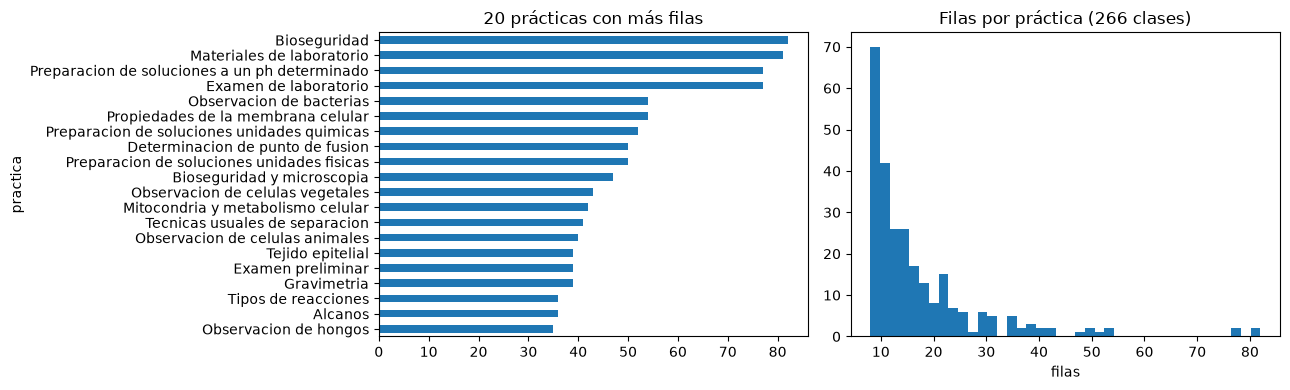

In [5]:
conteo = datos['practica'].value_counts()
print(conteo.describe())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
conteo.head(20).iloc[::-1].plot.barh(ax=ax[0], title='20 prácticas con más filas')
ax[1].hist(conteo, bins=40)
ax[1].set_title('Filas por práctica (266 clases)')
ax[1].set_xlabel('filas')
plt.tight_layout()

## 4. Longitud de los textos

Muchos nombres tienen una o dos palabras («bioseguridad», «alcanos»): la API los acepta.

count    4565.000000
mean        3.636802
std         2.129969
min         1.000000
25%         2.000000
50%         3.000000
75%         5.000000
max        13.000000
Name: texto, dtype: float64
una sola palabra: 677


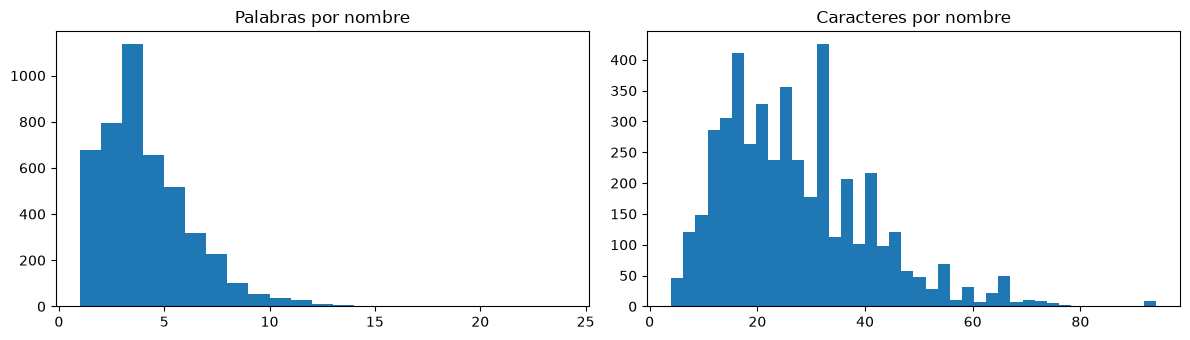

In [6]:
palabras = datos['texto'].str.split().str.len()
caracteres = datos['texto'].str.len()
print(palabras.describe())
print('una sola palabra:', int((palabras == 1).sum()))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(palabras, bins=range(1, 25))
ax[0].set_title('Palabras por nombre')
ax[1].hist(caracteres, bins=40)
ax[1].set_title('Caracteres por nombre')
plt.tight_layout()

## 5. Palabras más frecuentes, antes y después de quitar stop words

In [7]:
from src.nlp.preprocesamiento import normalizar, tokenizar, quitar_stop_words
tokens = [t for x in datos['texto'] for t in tokenizar(normalizar(x))]
sin_stop = [t for x in datos['texto'] for t in quitar_stop_words(tokenizar(normalizar(x)))]
pd.DataFrame({'con stop words': [f'{w} ({n})' for w, n in Counter(tokens).most_common(15)],
              'sin stop words': [f'{w} ({n})' for w, n in Counter(sin_stop).most_common(15)]})

,con stop words,sin stop words
0,de (2865),soluciones (367)
1,y (506),preparacion (356)
2,soluciones (367),determinacion (293)
3,preparacion (356),laboratorio (218)
4,del (324),observacion (202)
5,determinacion (293),propiedades (190)
6,la (235),obtencion (174)
7,laboratorio (218),examen (169)
8,observacion (202),bioseguridad (148)
9,propiedades (190),tejido (134)


## 6. Reactivos que salen en casi todas las prácticas

Por eso la sugerencia de reactivos usa la proporción de sesiones **de esa práctica**, no «todo lo que alguna vez la acompañó».

In [8]:
sesiones = kardex.groupby('reactivo')['nombre'].nunique().sort_values(ascending=False)
sesiones.head(10).rename('prácticas distintas')

reactivo
ETANOL AL 96%            307
ACEITE DE INMERSION      188
ACIDO CLORIHIDRICO       136
ACIDO SULFURICO           91
HIDROXIDO DE SODIO        65
CLORURO DE SODIO TEC      63
VASELINA SOLIDA           56
ACIDO ACETICO GLACIAL     54
ACIDO NITRICO             51
ACEITE COMESTIBLE         49
Name: prácticas distintas, dtype: int64

## 7. Preprocesamiento antes / después

In [9]:
from src.nlp.preprocesamiento import pasos
ejemplos = ['PREPARACIÓN DE SOLUCIONES DE UN PH DETERMINADO', 'LAB 4 PREPARACION DE SOLUCIONES UNIDADES FISICAS',
            'INTRODUCCIÒN A LA BIOTECNOLOGÌA', 'preparacion de soluciones de un phdeterminado', 'Observación de células animales 🔬']
pd.DataFrame([{**{k: pasos(e, 'stem')[k] for k in ('original', 'normalizado')},
               'stem': pasos(e, 'stem')['texto_final'], 'lemma': pasos(e, 'lemma')['texto_final']} for e in ejemplos])

,original,normalizado,stem,lemma
0,PREPARACIÓN DE SOLUCIONES DE UN PH DETERMINADO,preparación de soluciones de un ph determinado,prepar solucion ph determin,preparacion solucion ph determinado
1,LAB 4 PREPARACION DE SOLUCIONES UNIDADES FISICAS,lab preparacion de soluciones unidades fisicas,prepar solucion unidad fisic,preparacion solucion unidad fisica
2,INTRODUCCIÒN A LA BIOTECNOLOGÌA,introducción a la biotecnología,introduccion biotecnolog,introduccion biotecnologio
3,preparacion de soluciones de un phdeterminado,preparacion de soluciones de un phdeterminado,prepar solucion phdetermin,preparacion solucion phdeterminado
4,Observación de células animales 🔬,observación de células animales,observ celul animal,observacion celulas animal


Casos difíciles de tokenización: `phdeterminado` (dos palabras pegadas), `ac` por «ácido», `e coli` (la `e` suelta se descarta como letra sola), `lab 4` (el número se quita y `lab` es stop word del dominio). La lematización de spaCy falla con términos técnicos (`biotecnología` → `biotecnologio`).

## 8. Experimentos (validación cruzada, macro-F1)

In [10]:
exp = pd.read_csv('../models/experimentos.csv')
exp.pivot_table(index=['modo', 'ngramas'], columns='modelo', values='f1_macro_cv')

modelo            complement_nb  logistica  multinomial_nb
modo  ngramas                                             
lemma uni                0.5152     0.7127          0.4469
      uni+bi             0.5634     0.6530          0.4545
      uni+bi+car         0.6452     0.8727          0.5767
stem  uni                0.5278     0.7439          0.4919
      uni+bi             0.5969     0.6910          0.4874
      uni+bi+car         0.6547     0.8415          0.5846

Los n-gramas de caracteres son los que más suben: absorben errores de tipeo (`fisecas`, `prepraracion`) que con palabras completas quedan fuera del vocabulario. Los bigramas de palabras solos no ayudan a la regresión logística; sí a Naive Bayes.

In [11]:
m = json.load(open('../models/metricas.json', encoding='utf-8'))
filas = []
for k in ('logistica', 'complement_nb', 'regla_similitud', 'linea_base'):
    r = m['modelos'][k]
    filas.append({'modelo': k, 'f1_cv': r.get('f1_macro_cv'), 'f1_prueba': r['prueba']['f1_macro'], 'exactitud_prueba': r['prueba']['exactitud'],
                  'f1_manual': r['prueba_manual']['f1_macro'], 'exactitud_manual': r['prueba_manual']['exactitud']})
pd.DataFrame(filas)

,modelo,f1_cv,f1_prueba,exactitud_prueba,f1_manual,exactitud_manual
0,logistica,0.8871,0.9264,0.9698,0.8374,0.9024
1,complement_nb,0.6889,0.7413,0.8709,0.7887,0.8780
2,regla_similitud,NaN,1.0000,1.0000,0.5528,0.7561
3,linea_base,NaN,0.0001,0.0027,0.0014,0.0366


## 9. Análisis de errores (prueba manual)

In [12]:
pd.DataFrame(m['errores_prueba_manual']['ejemplos'])

,texto,practica,prediccion,probabilidad
0,TOMA DE MUESTRA DE SANGRE,Toma de muestra sanguinea,Toma de muestra,0.303
1,PREPARACION DE SOLUCIONES DE UN PHDETERMINADO,Preparacion de soluciones a un ph determinado,Preparacion de soluciones,0.160
2,TECNICAS USUALES DE SEPARACION EXPERIENCIA #2: SEPARACION SOLIDO-SOLIDO,Tecnicas usuales de separacion,Tecnicas de separacion solido-solido,0.156
3,PREPARACION DE SOLUCIONES BUFFER,Preparacion de soluciones tampon,Preparacion de soluciones,0.169
4,PREPARACION DE UNA DILUCION,Preparacion de soluciones por dilucion,Diluciones,0.144
5,PREPARACION DE SOLUCIONES - DILUSION,Preparacion de soluciones por dilucion,Preparacion de soluciones,0.177
6,"EXAMEN GENERAL DE ORINA, HCG",Examen general de orina (microscopia),Examen general de orina,0.106
7,1 HCG 2 EXAMEN GENERAL DE ORINA,Examen general de orina (microscopia),Examen general de orina,0.357


In [13]:
pd.DataFrame(m['errores']['confusiones_frecuentes'])

,real,predicha,veces
0,Uso y control de la micripipeta,Uso de la micropipeta,2
1,Bioseguridad y microscopia,Bioseguridad,1
2,Bioseguridad y microscopia,Examen de microscopia,1
3,Division celular-mitosis,Mitosis,1
4,Microscopia,Examen de microscopia,1
5,Preparacion de soluciones unidades quimicas,Preparacion de soluciones,1
